# 02_model_05：日级摘要预测与 10 分钟日内负荷曲线重构

## 本 notebook 预测什么

原始数据保持 **10 分钟粒度**，但调度需要的是未来一天的负荷形状，而不是只预测下一个 10 分钟点。因此采用两层方案：

1. **日级摘要预测**：用截至当天已知的信息，预测下一天的总用电量、平均负荷、峰值、谷值、峰值时段和谷值时段；
2. **日内曲线重构**：从历史 10 分钟负荷曲线中提取与目标日相似的日内形状，再根据第一层预测出的日总量和峰值进行缩放与校准，得到下一天 144 个 10 分钟负荷预测值。

这样既保留了 10 分钟的时间分辨率，又能直接回答“明天需要多少电、峰值多大、峰谷什么时候出现，以及每个 10 分钟点大约是多少”。

## 建模对象和评价原则

每天由 144 个 10 分钟负荷点组成。日级目标包括：

- **日用电量**：144 个负荷点乘以 `1/6` 小时后的总和，单位为 kWh；
- **日平均负荷**：当天 144 个点的平均值；
- **日峰值和日谷值**：当天 10 分钟负荷的最大值和最小值；
- **高峰期和低谷期**：用连续 1 小时的滑动平均负荷定义峰值/谷值，更稳定地反映调度时段；
- **峰值时段和谷值时段**：对应的 10 分钟时间槽编号，0 表示 00:00，143 表示 23:50。

模型预测的是下一天，因此所有训练标签都向后移动 1 天。评价时既看摘要指标误差，也看重构出的 144 点曲线误差。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
FIG_DIR = 'figures'
VAL_START = pd.Timestamp('2017-10-01')
SPLIT = pd.Timestamp('2017-11-01')
MODEL_NAMES = ['线性回归', '随机森林']
SUMMARY_TARGETS = [
    'energy_kwh', 'mean_kw', 'peak_kw', 'valley_kw',
    'peak_1h_kw', 'valley_1h_kw',
    'peak_slot', 'valley_slot', 'peak_1h_slot', 'valley_1h_slot'
]
SEEDS = [0, 1, 2]
N_EST = 100
print('pandas', pd.__version__, '| sklearn', __import__('sklearn').__version__)
print('建模粒度：10分钟；日内点数：144；预测步长：1天')

pandas 3.0.3 | sklearn 1.9.0
建模粒度：10分钟；日内点数：144；预测步长：1天


## 1. 数据读取与 10 分钟粒度检查

In [2]:
df = pd.read_csv('data/题4_城市电力负荷.csv', encoding='utf-8-sig')
df.columns = ['DateTime', 'T', 'RH', 'WS', 'GDF', 'DF', 'Z1', 'Z2', 'Z3']
df['DateTime'] = pd.to_datetime(df['DateTime'], format='%m/%d/%Y %H:%M')
df = df.set_index('DateTime').sort_index()
df['Z_total'] = df[['Z1', 'Z2', 'Z3']].sum(axis=1)
assert df.index.is_monotonic_increasing
assert not df.index.duplicated().any()
assert df.isna().sum().sum() == 0

step_minutes = df.index.to_series().diff().dropna().dt.total_seconds().div(60)
assert step_minutes.eq(10).all(), f'发现非 10 分钟间隔：{step_minutes.value_counts().head()}'
print('样本数:', len(df))
print('时间范围:', df.index.min(), '->', df.index.max())
print('采样间隔（分钟）:', step_minutes.mode().iloc[0])

样本数: 52416
时间范围: 2017-01-01 00:00:00 -> 2017-12-30 23:50:00
采样间隔（分钟）: 10.0


## 2. 从 10 分钟数据构造日级摘要

日级摘要只使用当天结束时已经知道的信息。对于预测下一天，当前日的负荷和天气摘要可以作为输入；目标日的真实天气不会进入模型特征。

In [3]:
def slot_to_clock(slot):
    slot = int(np.clip(round(slot), 0, 143))
    return f'{slot // 6:02d}:{(slot % 6) * 10:02d}'

records = []
day_profiles = {}
for day, group in df['Z_total'].groupby(df.index.normalize()):
    values = group.to_numpy(dtype=float)
    if len(values) != 144:
        continue
    day_profiles[pd.Timestamp(day)] = values
    rolling_1h = pd.Series(values).rolling(6).mean().to_numpy()
    peak_1h_slot = int(np.nanargmax(rolling_1h))
    valley_1h_slot = int(np.nanargmin(rolling_1h))
    records.append({
        'date': pd.Timestamp(day),
        'energy_kwh': values.sum() / 6,
        'mean_kw': values.mean(),
        'peak_kw': values.max(),
        'valley_kw': values.min(),
        'peak_1h_kw': np.nanmax(rolling_1h),
        'valley_1h_kw': np.nanmin(rolling_1h),
        'peak_slot': int(values.argmax()),
        'valley_slot': int(values.argmin()),
        'peak_1h_slot': peak_1h_slot,
        'valley_1h_slot': valley_1h_slot,
        'sample_count': len(values),
    })

daily = pd.DataFrame(records).set_index('date').sort_index()
weather_daily = df[['T', 'RH', 'WS', 'GDF', 'DF']].resample('D').agg(['mean', 'max', 'min'])
weather_daily.columns = [f'weather_{c}_{stat}' for c, stat in weather_daily.columns]
daily = daily.join(weather_daily, how='left')
daily = daily[daily['sample_count'] == 144].copy()

daily_summary = daily[['energy_kwh', 'mean_kw', 'peak_kw', 'valley_kw',
                       'peak_1h_kw', 'valley_1h_kw']].describe().T
display(daily_summary.style.format('{:,.1f}'))
print('完整天数:', len(daily))

,count,mean,std,min,25%,50%,75%,max
energy_kwh,364.0,"1,709,349.3","199,421.9","1,405,779.6","1,588,912.9","1,642,864.3","1,748,725.5","2,353,184.2"
mean_kw,364.0,"71,222.9","8,309.2","58,574.2","66,204.7","68,452.7","72,863.6","98,049.3"
peak_kw,364.0,"99,644.1","10,905.8","79,329.7","92,855.5","96,356.2","102,074.9","134,208.1"
valley_kw,364.0,"47,207.8","4,916.8","36,785.0","44,170.8","46,689.5","49,614.5","63,164.7"
peak_1h_kw,364.0,"99,011.6","10,751.5","78,934.0","92,454.9","95,788.3","100,407.5","133,129.8"
valley_1h_kw,364.0,"47,944.4","4,935.5","37,340.0","44,996.1","47,344.3","50,087.7","63,812.2"


完整天数: 364


## 3. 日级特征：只使用预测时可获得的信息

输入特征包括：

- 前 1 天、前 7 天、前 14 天和前 28 天的日负荷摘要；
- 当前日及历史日的天气摘要。这里的“当前日”是预测下一天时已经结束并可获得的天气；
- 下一天的星期、月份和周末标记，这些日历信息提前已知。

未来目标日的真实温度、湿度、风速和辐射不作为输入。实际部署时，可以把当前日天气特征替换成气象预报特征。

In [4]:
load_summary_cols = ['energy_kwh', 'mean_kw', 'peak_kw', 'valley_kw',
                     'peak_1h_kw', 'valley_1h_kw']
weather_cols = [c for c in daily.columns if c.startswith('weather_')]
FEATURES = []

for col in load_summary_cols:
    for lag in [1, 7, 14, 28]:
        name = f'{col}_lag_{lag}'
        daily[name] = daily[col].shift(lag)
        FEATURES.append(name)

for col in weather_cols:
    for lag in [0, 1, 7]:
        name = f'{col}_lag_{lag}'
        daily[name] = daily[col].shift(lag)
        FEATURES.append(name)

target_day = daily.index + pd.Timedelta(days=1)
daily['target_date'] = target_day
daily['target_dow'] = target_day.dayofweek
daily['target_month'] = target_day.month
daily['target_is_weekend'] = (target_day.dayofweek >= 5).astype(int)
daily['target_dow_sin'] = np.sin(2 * np.pi * target_day.dayofweek / 7)
daily['target_dow_cos'] = np.cos(2 * np.pi * target_day.dayofweek / 7)
daily['target_month_sin'] = np.sin(2 * np.pi * (target_day.month - 1) / 12)
daily['target_month_cos'] = np.cos(2 * np.pi * (target_day.month - 1) / 12)
FEATURES += ['target_dow', 'target_month', 'target_is_weekend',
             'target_dow_sin', 'target_dow_cos',
             'target_month_sin', 'target_month_cos']

# 目标是下一天的摘要，而不是当前日摘要；输入仍然只来自当前日及更早信息。
TARGET_COLUMNS = []
for col in SUMMARY_TARGETS:
    target_col = f'target_{col}'
    daily[target_col] = daily[col].shift(-1)
    TARGET_COLUMNS.append(target_col)

model_df = daily.dropna(subset=FEATURES + TARGET_COLUMNS).copy()
train_df = model_df[model_df['target_date'] < SPLIT].copy()
test_df = model_df[model_df['target_date'] >= SPLIT].copy()
fit_df = train_df[train_df['target_date'] < VAL_START].copy()
val_df = train_df[train_df['target_date'] >= VAL_START].copy()

print('训练样本:', len(train_df), '| 验证样本:', len(val_df), '| 测试样本:', len(test_df))
print('测试目标日期:', test_df['target_date'].min(), '->', test_df['target_date'].max())

训练样本: 275 | 验证样本: 31 | 测试样本: 60
测试目标日期: 2017-11-01 00:00:00 -> 2017-12-30 00:00:00


## 4. 日级摘要模型与时间顺序验证

对于每一个摘要目标，分别比较线性回归和受限随机森林。随机森林设置较浅的树、较大的叶节点和较少的特征子采样，以降低日级样本较少时的过拟合风险。模型选择只使用 10 月验证集，11—12 月测试集只用于最后评价。

In [5]:
def make_model(name, seed):
    if name == '线性回归':
        return LinearRegression(), True
    if name == '随机森林':
        return RandomForestRegressor(
            n_estimators=N_EST, max_depth=6, min_samples_leaf=5,
            max_features='sqrt', n_jobs=1, random_state=seed
        ), False
    raise ValueError(name)

def fit_predict(model, Xtr, ytr, Xte, scale):
    if scale:
        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr)
        Xte = scaler.transform(Xte)
    model.fit(Xtr, ytr)
    return model.predict(Xte), model

def rmse(y_true, pred):
    return float(np.sqrt(mean_squared_error(y_true, pred)))

selection_rows = []
selected_models = {}
for target_col in TARGET_COLUMNS:
    target_name = target_col.replace('target_', '')
    target_scores = []
    for name in MODEL_NAMES:
        model, scale = make_model(name, 0)
        pred, _ = fit_predict(model, fit_df[FEATURES], fit_df[target_col], val_df[FEATURES], scale)
        score = rmse(val_df[target_col], pred)
        mae = mean_absolute_error(val_df[target_col], pred)
        target_scores.append((score, name))
        selection_rows.append({'目标': target_name, '模型': name, '验证RMSE': score, '验证MAE': mae})
    selected_models[target_col] = min(target_scores)[1]

selection_df = pd.DataFrame(selection_rows)
display(selection_df.pivot(index='目标', columns='模型', values='验证RMSE').style.format('{:,.2f}'))
print('各目标冻结模型:', {k.replace('target_', ''): v for k, v in selected_models.items()})

模型,线性回归,随机森林
目标,,
energy_kwh,"64,403.32","36,613.27"
mean_kw,"2,683.47","1,530.85"
peak_1h_kw,"3,673.10","2,338.20"
peak_1h_slot,6.02,4.30
peak_kw,"3,540.13","2,435.06"
peak_slot,6.28,5.49
valley_1h_kw,"3,763.35","3,368.37"
valley_1h_slot,9.45,7.27
valley_kw,"3,637.16","3,256.55"


各目标冻结模型: {'energy_kwh': '随机森林', 'mean_kw': '随机森林', 'peak_kw': '随机森林', 'valley_kw': '随机森林', 'peak_1h_kw': '随机森林', 'valley_1h_kw': '随机森林', 'peak_slot': '随机森林', 'valley_slot': '随机森林', 'peak_1h_slot': '随机森林', 'valley_1h_slot': '随机森林'}


In [6]:
summary_predictions = {}
summary_metrics = []
for target_col in TARGET_COLUMNS:
    target_name = target_col.replace('target_', '')
    name = selected_models[target_col]
    model, scale = make_model(name, 0)
    pred, _ = fit_predict(model, train_df[FEATURES], train_df[target_col], test_df[FEATURES], scale)
    summary_predictions[target_name] = pred
    summary_metrics.append({
        '目标': target_name,
        '模型': name,
        'RMSE': rmse(test_df[target_col], pred),
        'MAE': mean_absolute_error(test_df[target_col], pred),
    })

summary_metrics_df = pd.DataFrame(summary_metrics)
display(summary_metrics_df.style.format({'RMSE': '{:,.2f}', 'MAE': '{:,.2f}'}))

summary_result = pd.DataFrame({
    '目标日期': test_df['target_date'].to_numpy(),
    '真实日用电量(kWh)': test_df['target_energy_kwh'].to_numpy(),
    '预测日用电量(kWh)': summary_predictions['energy_kwh'],
    '真实峰值(kW)': test_df['target_peak_kw'].to_numpy(),
    '预测峰值(kW)': summary_predictions['peak_kw'],
    '真实谷值(kW)': test_df['target_valley_kw'].to_numpy(),
    '预测谷值(kW)': summary_predictions['valley_kw'],
    '真实峰值时段': [slot_to_clock(x) for x in test_df['target_peak_slot']],
    '预测峰值时段': [slot_to_clock(x) for x in summary_predictions['peak_slot']],
    '真实谷值时段': [slot_to_clock(x) for x in test_df['target_valley_slot']],
    '预测谷值时段': [slot_to_clock(x) for x in summary_predictions['valley_slot']],
})
display(summary_result.head(10))

,目标,模型,RMSE,MAE
0,energy_kwh,随机森林,"70,113.52","59,749.60"
1,mean_kw,随机森林,"2,916.12","2,484.11"
2,peak_kw,随机森林,"5,474.45","5,012.64"
3,valley_kw,随机森林,"2,819.52","2,020.76"
4,peak_1h_kw,随机森林,"5,411.75","4,908.01"
5,valley_1h_kw,随机森林,"2,696.59","1,888.31"
6,peak_slot,随机森林,6.73,6.21
7,valley_slot,随机森林,9.45,7.42
8,peak_1h_slot,随机森林,6.08,5.69
9,valley_1h_slot,随机森林,10.10,8.56


,目标日期,真实日用电量(kWh),预测日用电量(kWh),真实峰值(kW),预测峰值(kW),真实谷值(kW),预测谷值(kW),真实峰值时段,预测峰值时段,真实谷值时段,预测谷值时段
0,2017-11-01,1.597872e+06,1.633207e+06,92798.10981,95543.871930,45738.593053,48077.034363,18:10,18:50,06:40,06:40
1,2017-11-02,1.584514e+06,1.640026e+06,92238.08248,95970.423321,45151.083652,48036.542331,18:20,19:00,06:40,06:20
2,2017-11-03,1.570187e+06,1.631706e+06,89825.57916,94851.285193,45013.185765,48187.852987,18:50,19:20,06:40,06:30
3,2017-11-04,1.570291e+06,1.604348e+06,90685.63722,93351.489129,44123.042069,45049.431504,18:30,19:20,06:50,06:20
4,2017-11-05,1.456214e+06,1.559549e+06,84139.25443,93030.634489,38569.349483,42599.270892,18:50,19:40,06:50,06:20
5,2017-11-06,1.494925e+06,1.624500e+06,88121.70375,95546.412854,39059.468514,46575.324350,18:10,19:40,07:00,06:10
6,2017-11-07,1.550116e+06,1.637052e+06,90632.95468,96010.726805,45095.013366,47248.799735,18:50,19:20,06:40,06:10
7,2017-11-08,1.614878e+06,1.640665e+06,99297.46459,95911.806593,44062.207431,47501.351994,18:00,19:20,06:40,06:10
8,2017-11-09,1.639781e+06,1.646641e+06,93898.81479,96429.640009,45010.100875,47582.196244,17:50,19:10,06:40,06:10
9,2017-11-10,1.592700e+06,1.632467e+06,90369.02405,94983.645444,45004.819963,47537.081142,18:20,19:10,06:50,06:10


## 5. 第二层：用历史曲线重构下一天的 144 个 10 分钟点

先将历史完整日曲线除以当天平均负荷，得到只描述“形状”的归一化曲线。模板按星期几求平均，并且只使用 11 月之前的历史天，避免把测试期真实曲线泄漏给模型。

对测试日，选择对应星期的历史形状：

1. 按预测日的星期几对齐曲线；
2. 用预测日用电量把曲线缩放到正确的能量水平；
3. 用预测峰值调整曲线振幅，并再次归一化，保证日用电量与第一层预测一致；
4. 输出完整的 144 点预测曲线。

预测出的谷值和峰谷时段作为曲线校验信息；如果需要严格满足多项约束，可以在此基础上增加带上下界的优化校准。

In [7]:
# 只使用训练期历史日建立星期模板
weekday_shapes = {}
all_shapes = []
for day, values in day_profiles.items():
    day = pd.Timestamp(day)
    if day >= SPLIT:
        continue
    shape = values / values.mean()
    all_shapes.append(shape)
    weekday_shapes.setdefault(day.dayofweek, []).append(shape)

weekday_shapes = {k: np.mean(v, axis=0) for k, v in weekday_shapes.items()}
global_shape = np.mean(all_shapes, axis=0)

def reconstruct_profile(shape, energy_kwh, peak_kw, peak_slot=None):
    shape = np.maximum(np.asarray(shape, dtype=float), 1e-6)
    shape = shape / shape.mean()
    if peak_slot is not None:
        shift = int(np.clip(round(peak_slot), 0, 143)) - int(np.argmax(shape))
        shape = np.roll(shape, shift)

    # 先按预测日用电量缩放，平均负荷为 energy/24。
    curve = shape * (max(float(energy_kwh), 0.0) / 24.0)
    target_mean = max(float(energy_kwh), 0.0) / 24.0
    current_peak = curve.max()
    if current_peak > target_mean and peak_kw > target_mean:
        # 调整相对平均值的振幅，再恢复日用电量。
        gain = np.clip((float(peak_kw) - target_mean) / (current_peak - target_mean), 0.25, 3.0)
        curve = target_mean + gain * (curve - target_mean)
        curve = np.maximum(curve, 0.0)
        curve *= max(float(energy_kwh), 0.0) / max(curve.sum() / 6.0, 1e-9)
    return curve

forecast_curves = []
actual_curves = []
curve_dates = []
for i, (_, row) in enumerate(test_df.iterrows()):
    target_date = pd.Timestamp(row['target_date'])
    shape = weekday_shapes.get(target_date.dayofweek, global_shape)
    curve = reconstruct_profile(
        shape,
        summary_predictions['energy_kwh'][i],
        summary_predictions['peak_kw'][i],
        summary_predictions['peak_slot'][i]
    )
    if target_date in day_profiles:
        forecast_curves.append(curve)
        actual_curves.append(day_profiles[target_date])
        curve_dates.append(target_date)

forecast_curves = np.asarray(forecast_curves)
actual_curves = np.asarray(actual_curves)
curve_rmse = np.sqrt(np.mean((actual_curves - forecast_curves) ** 2))
print('完整日内曲线数量:', len(curve_dates))
print('144点曲线总体 RMSE:', round(curve_rmse, 2), 'kW')

curve_metrics = pd.DataFrame({
    '目标': ['重构日用电量', '重构日峰值'],
    '真实值平均': [actual_curves.sum(axis=1).mean() / 6, actual_curves.max(axis=1).mean()],
    '预测值平均': [forecast_curves.sum(axis=1).mean() / 6, forecast_curves.max(axis=1).mean()],
    'RMSE': [
        rmse(actual_curves.sum(axis=1) / 6, forecast_curves.sum(axis=1) / 6),
        rmse(actual_curves.max(axis=1), forecast_curves.max(axis=1)
    )]
})
display(curve_metrics.style.format({'真实值平均': '{:,.2f}', '预测值平均': '{:,.2f}', 'RMSE': '{:,.2f}'}))

完整日内曲线数量: 60
144点曲线总体 RMSE: 5011.54 kW


,目标,真实值平均,预测值平均,RMSE
0,重构日用电量,"1,546,270.74","1,605,654.59","70,113.52"
1,重构日峰值,"89,663.47","94,563.26","5,474.45"


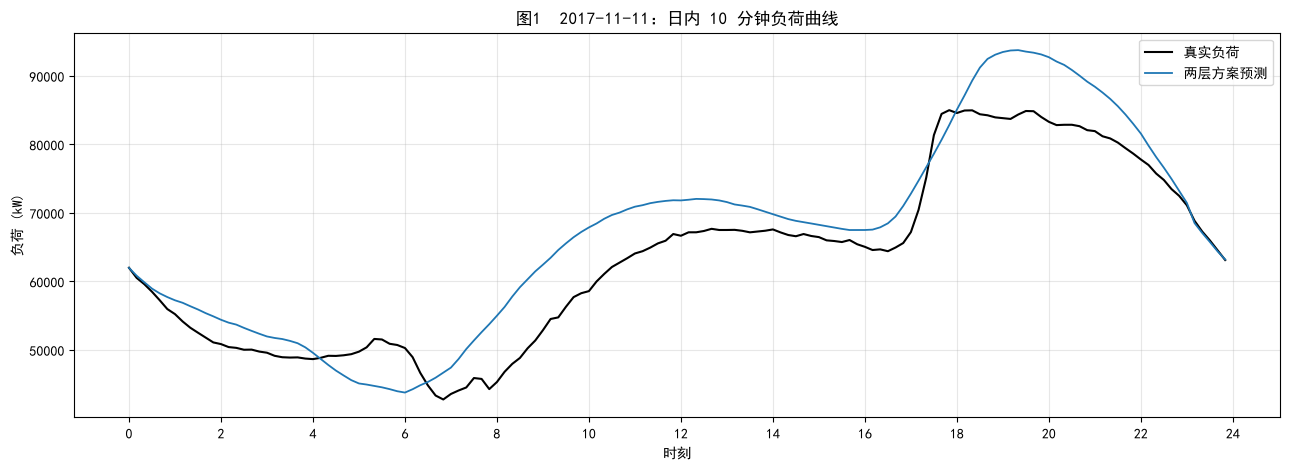

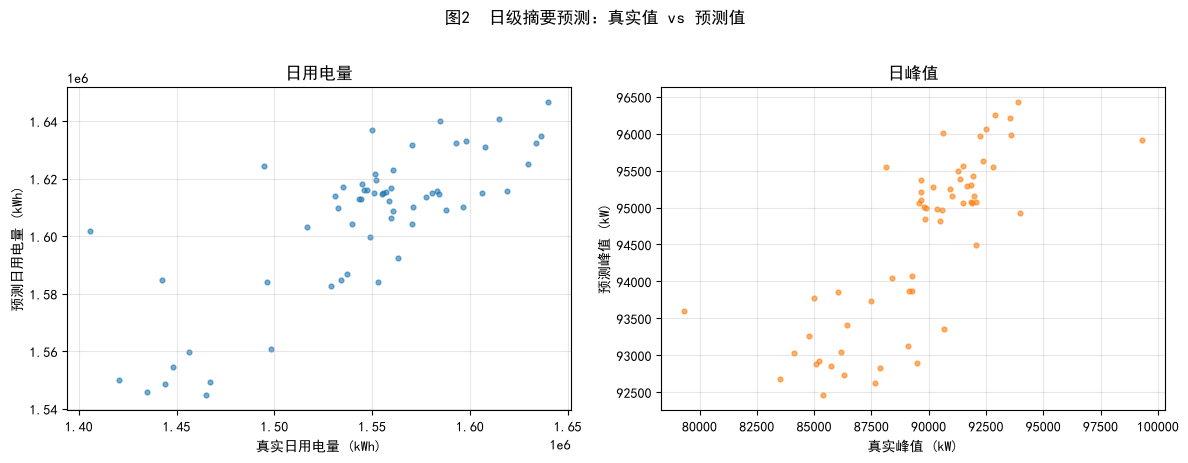

In [8]:
# 图1：示例测试日的 10 分钟负荷曲线
example_idx = min(10, len(curve_dates) - 1)
fig, ax = plt.subplots(figsize=(13, 4.8))
slot_axis = np.arange(144) / 6
ax.plot(slot_axis, actual_curves[example_idx], color='black', lw=1.5, label='真实负荷')
ax.plot(slot_axis, forecast_curves[example_idx], color='#1f77b4', lw=1.3, label='两层方案预测')
ax.set_title(f'图1  {curve_dates[example_idx].date()}：日内 10 分钟负荷曲线')
ax.set_xlabel('时刻'); ax.set_ylabel('负荷 (kW)')
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B05_day_curve.png', dpi=160, bbox_inches='tight'); plt.show()

# 图2：日摘要预测误差
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(summary_result['真实日用电量(kWh)'], summary_result['预测日用电量(kWh)'], s=12, alpha=0.6)
axes[0].set_xlabel('真实日用电量 (kWh)'); axes[0].set_ylabel('预测日用电量 (kWh)'); axes[0].set_title('日用电量')
axes[1].scatter(summary_result['真实峰值(kW)'], summary_result['预测峰值(kW)'], s=12, alpha=0.6, color='#ff7f0e')
axes[1].set_xlabel('真实峰值 (kW)'); axes[1].set_ylabel('预测峰值 (kW)'); axes[1].set_title('日峰值')
for ax in axes: ax.grid(alpha=0.3)
fig.suptitle('图2  日级摘要预测：真实值 vs 预测值', y=1.02); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B05_daily_summary.png', dpi=160, bbox_inches='tight'); plt.show()

## 5.1 两种模型的直接对比评价

上一节为了得到最终预测，针对每个摘要目标冻结了验证集上表现更好的模型。这里重新在相同的训练集和测试集上运行 **线性回归** 与 **随机森林**，让两个模型在每一个目标上直接对比。

- 连续负荷目标：RMSE、MAE、sMAPE、归一化 RMSE 和 R²；
- 峰谷时段目标：平均误差和 RMSE 都换算成分钟，并统计预测落在真实时段前后 1 小时内的比例；
- 最后比较两个模型重构出的完整 144 点日内曲线误差。

In [9]:
CONTINUOUS_TARGETS = [
    'energy_kwh', 'mean_kw', 'peak_kw', 'valley_kw',
    'peak_1h_kw', 'valley_1h_kw'
]
PERIOD_TARGETS = ['peak_slot', 'valley_slot', 'peak_1h_slot', 'valley_1h_slot']

def smape(y_true, pred):
    y_true = np.asarray(y_true, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return float(np.mean(2 * np.abs(pred - y_true) /
                        (np.abs(y_true) + np.abs(pred) + 1e-9)) * 100)

comparison_predictions = {}
comparison_rows = []
for target_name in SUMMARY_TARGETS:
    target_col = f'target_{target_name}'
    y_true = test_df[target_col].to_numpy()
    for model_name in MODEL_NAMES:
        model, scale = make_model(model_name, 0)
        pred, _ = fit_predict(model, train_df[FEATURES], train_df[target_col], test_df[FEATURES], scale)
        comparison_predictions[(model_name, target_name)] = pred
        row = {'模型': model_name, '目标': target_name}
        if target_name in CONTINUOUS_TARGETS:
            row.update({
                'RMSE': rmse(y_true, pred),
                'MAE': mean_absolute_error(y_true, pred),
                'sMAPE%': smape(y_true, pred),
                '归一化RMSE%': rmse(y_true, pred) / np.mean(np.abs(y_true)) * 100,
                'R2': r2_score(y_true, pred),
            })
        else:
            abs_error_slots = np.abs(pred - y_true)
            row.update({
                'RMSE分钟': rmse(y_true, pred) * 10,
                'MAE分钟': mean_absolute_error(y_true, pred) * 10,
                '±60分钟命中率%': np.mean(abs_error_slots <= 6) * 100,
            })
        comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
comparison_continuous = comparison_df[comparison_df['目标'].isin(CONTINUOUS_TARGETS)][
    ['模型', '目标', 'RMSE', 'MAE', 'sMAPE%', '归一化RMSE%', 'R2']
].copy()
comparison_period = comparison_df[comparison_df['目标'].isin(PERIOD_TARGETS)][
    ['模型', '目标', 'RMSE分钟', 'MAE分钟', '±60分钟命中率%']
].copy()

display(comparison_continuous.style.format({
    'RMSE': '{:,.2f}', 'MAE': '{:,.2f}', 'sMAPE%': '{:.2f}%',
    '归一化RMSE%': '{:.2f}%', 'R2': '{:.4f}'
}))
display(comparison_period.style.format({
    'RMSE分钟': '{:,.1f}', 'MAE分钟': '{:,.1f}', '±60分钟命中率%': '{:.1f}%'
}))

,模型,目标,RMSE,MAE,sMAPE%,归一化RMSE%,R2
0,线性回归,energy_kwh,"111,804.91","93,550.86",6.31%,7.23%,-3.2381
1,随机森林,energy_kwh,"70,113.52","59,749.60",3.84%,4.53%,-0.6667
2,线性回归,mean_kw,"4,658.54","3,897.95",6.31%,7.23%,-3.2381
3,随机森林,mean_kw,"2,916.12","2,484.11",3.83%,4.53%,-0.6607
4,线性回归,peak_kw,"3,869.54","2,934.44",3.29%,4.32%,-0.4428
5,随机森林,peak_kw,"5,474.45","5,012.64",5.49%,6.11%,-1.8878
6,线性回归,valley_kw,"5,223.82","4,217.26",9.26%,11.83%,-1.4907
7,随机森林,valley_kw,"2,819.52","2,020.76",4.68%,6.39%,0.2744
8,线性回归,peak_1h_kw,"3,823.36","2,925.90",3.31%,4.28%,-0.5253
9,随机森林,peak_1h_kw,"5,411.75","4,908.01",5.40%,6.06%,-2.0559


,模型,目标,RMSE分钟,MAE分钟,±60分钟命中率%
12,线性回归,peak_slot,70.8,54.9,65.0%
13,随机森林,peak_slot,67.3,62.1,45.0%
14,线性回归,valley_slot,105.3,72.5,65.0%
15,随机森林,valley_slot,94.5,74.2,55.0%
16,线性回归,peak_1h_slot,46.6,34.8,80.0%
17,随机森林,peak_1h_slot,60.8,56.9,40.0%
18,线性回归,valley_1h_slot,99.6,82.7,40.0%
19,随机森林,valley_1h_slot,101.0,85.6,51.7%


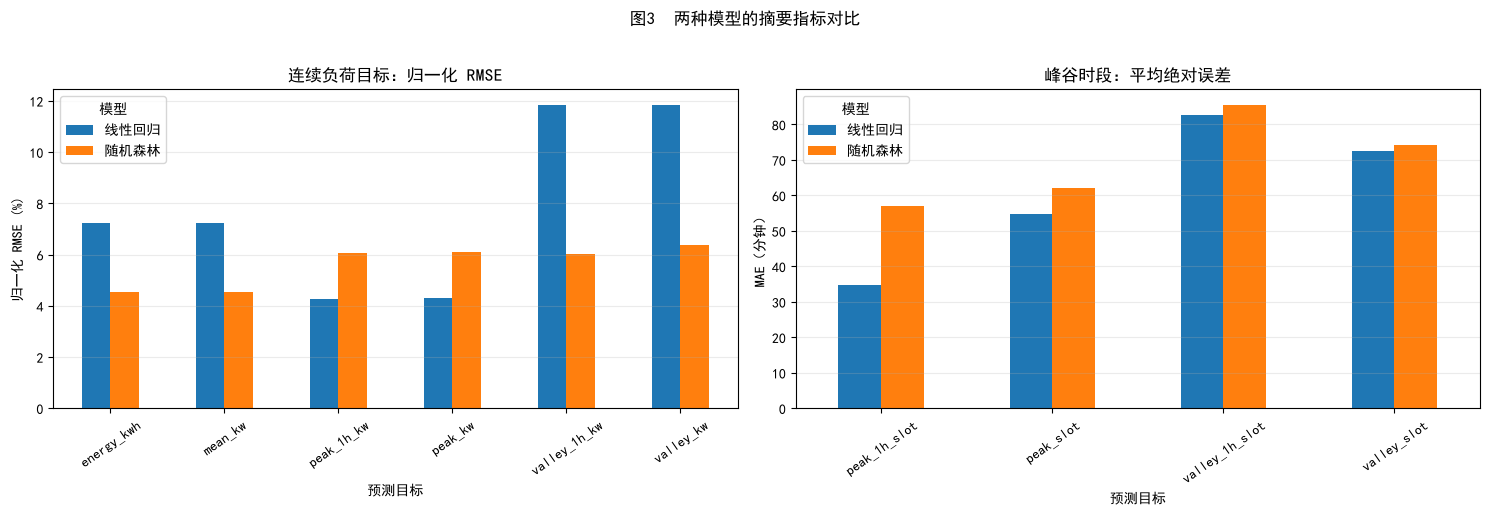

In [10]:
# 图3：两个模型在连续目标上的归一化 RMSE 对比，以及峰谷时段误差对比
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

nrmse_pivot = comparison_continuous.pivot(index='目标', columns='模型', values='归一化RMSE%')
nrmse_pivot.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title('连续负荷目标：归一化 RMSE')
axes[0].set_ylabel('归一化 RMSE (%)')
axes[0].set_xlabel('预测目标')
axes[0].tick_params(axis='x', rotation=35)
axes[0].grid(alpha=0.25, axis='y')
axes[0].legend(title='模型')

period_pivot = comparison_period.pivot(index='目标', columns='模型', values='MAE分钟')
period_pivot.plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e'])
axes[1].set_title('峰谷时段：平均绝对误差')
axes[1].set_ylabel('MAE（分钟）')
axes[1].set_xlabel('预测目标')
axes[1].tick_params(axis='x', rotation=35)
axes[1].grid(alpha=0.25, axis='y')
axes[1].legend(title='模型')
fig.suptitle('图3  两种模型的摘要指标对比', y=1.02)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B05_model_compare.png', dpi=160, bbox_inches='tight')
plt.show()

### 两种模型对完整日内曲线的比较

摘要指标之外，调度更关心 144 个 10 分钟预测点整体是否贴近真实曲线。下面使用两个模型各自预测的日用电量、峰值和峰值时段，分别重构日内曲线，再比较曲线 RMSE、MAE 和日用电量误差。

,模型,曲线RMSE(kW),曲线MAE(kW),日用电量RMSE(kWh),日峰值RMSE(kW)
0,线性回归,"11,446.81","9,128.52","111,804.91","3,869.54"
1,随机森林,"5,011.54","4,111.68","70,113.52","5,474.45"


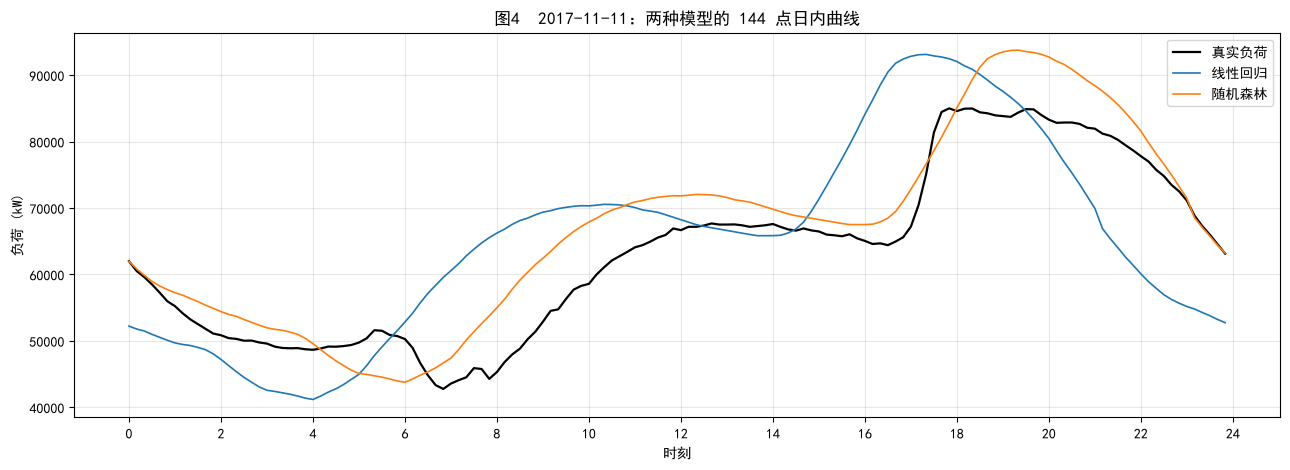

In [11]:
model_curve_rows = []
model_curve_predictions = {}
for model_name in MODEL_NAMES:
    curves = []
    actuals = []
    dates = []
    for i, (_, row) in enumerate(test_df.iterrows()):
        target_date = pd.Timestamp(row['target_date'])
        shape = weekday_shapes.get(target_date.dayofweek, global_shape)
        curve = reconstruct_profile(
            shape,
            comparison_predictions[(model_name, 'energy_kwh')][i],
            comparison_predictions[(model_name, 'peak_kw')][i],
            comparison_predictions[(model_name, 'peak_slot')][i]
        )
        if target_date in day_profiles:
            curves.append(curve)
            actuals.append(day_profiles[target_date])
            dates.append(target_date)

    curves = np.asarray(curves)
    actuals = np.asarray(actuals)
    model_curve_predictions[model_name] = curves
    model_curve_rows.append({
        '模型': model_name,
        '曲线RMSE(kW)': np.sqrt(np.mean((actuals - curves) ** 2)),
        '曲线MAE(kW)': np.mean(np.abs(actuals - curves)),
        '日用电量RMSE(kWh)': rmse(actuals.sum(axis=1) / 6, curves.sum(axis=1) / 6),
        '日峰值RMSE(kW)': rmse(actuals.max(axis=1), curves.max(axis=1)),
    })

model_curve_metrics = pd.DataFrame(model_curve_rows)
display(model_curve_metrics.style.format({
    '曲线RMSE(kW)': '{:,.2f}', '曲线MAE(kW)': '{:,.2f}',
    '日用电量RMSE(kWh)': '{:,.2f}', '日峰值RMSE(kW)': '{:,.2f}'
}))

# 图4：两个模型重构出的整日负荷曲线对比
example_idx = min(10, len(curve_dates) - 1)
fig, ax = plt.subplots(figsize=(13, 4.8))
slot_axis = np.arange(144) / 6
ax.plot(slot_axis, actual_curves[example_idx], color='black', lw=1.6, label='真实负荷')
for model_name, color in [('线性回归', '#1f77b4'), ('随机森林', '#ff7f0e')]:
    ax.plot(slot_axis, model_curve_predictions[model_name][example_idx],
            color=color, lw=1.2, label=model_name)
ax.set_title(f'图4  {curve_dates[example_idx].date()}：两种模型的 144 点日内曲线')
ax.set_xlabel('时刻'); ax.set_ylabel('负荷 (kW)')
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B05_model_curve_compare.png', dpi=160, bbox_inches='tight')
plt.show()

## 5.2 与朴素基线比较：判断模型是否真的有增益

模型误差必须和简单规则比较，否则无法判断复杂模型是否值得使用。这里使用三类日级基线：

- **前一天基线**：明天的摘要等于今天的摘要；
- **前一周基线**：明天的摘要等于上一周同一天的摘要；
- **训练期均值基线**：始终使用训练集目标均值。

日内曲线也分别使用前一天和前一周的 144 点曲线作为基线。只有当模型稳定优于这些基线时，才说明模型学到了额外的可泛化信息。

In [ ]:
# 日级摘要的朴素基线
baseline_rows = []
for target_name in CONTINUOUS_TARGETS:
    target_col = f'target_{target_name}'
    y_true = test_df[target_col].to_numpy()
    prev_day = test_df[target_name].to_numpy()
    prev_week = np.array([
        daily.loc[pd.Timestamp(d) - pd.Timedelta(days=6), target_name]
        for d in test_df.index
    ])
    train_mean = np.full(len(y_true), train_df[target_col].mean())

    for baseline_name, pred in [
        ('前一天基线', prev_day),
        ('前一周基线', prev_week),
        ('训练期均值基线', train_mean),
    ]:
        baseline_rows.append({
            '模型': baseline_name,
            '目标': target_name,
            'RMSE': rmse(y_true, pred),
            'MAE': mean_absolute_error(y_true, pred),
            'sMAPE%': smape(y_true, pred),
            '归一化RMSE%': rmse(y_true, pred) / np.mean(np.abs(y_true)) * 100,
        })

baseline_summary = pd.DataFrame(baseline_rows)
model_vs_baseline = pd.concat([
    comparison_continuous[['模型', '目标', 'RMSE', 'MAE', 'sMAPE%', '归一化RMSE%']],
    baseline_summary
], ignore_index=True)
display(model_vs_baseline.style.format({
    'RMSE': '{:,.2f}', 'MAE': '{:,.2f}', 'sMAPE%': '{:.2f}%', '归一化RMSE%': '{:.2f}%'
}))

In [ ]:
# 完整日内曲线的朴素基线
curve_baseline_rows = []
for baseline_name, delta in [('前一天曲线基线', 1), ('前一周曲线基线', 7)]:
    preds = []
    actuals = []
    for target_date in curve_dates:
        target_date = pd.Timestamp(target_date)
        preds.append(day_profiles[target_date - pd.Timedelta(days=delta)])
        actuals.append(day_profiles[target_date])
    preds = np.asarray(preds)
    actuals = np.asarray(actuals)
    curve_baseline_rows.append({
        '模型': baseline_name,
        '曲线RMSE(kW)': np.sqrt(np.mean((actuals - preds) ** 2)),
        '曲线MAE(kW)': np.mean(np.abs(actuals - preds)),
        '日用电量RMSE(kWh)': rmse(actuals.sum(axis=1) / 6, preds.sum(axis=1) / 6),
        '日峰值RMSE(kW)': rmse(actuals.max(axis=1), preds.max(axis=1)),
    })

curve_model_vs_baseline = pd.concat([
    model_curve_metrics,
    pd.DataFrame(curve_baseline_rows)
], ignore_index=True)
display(curve_model_vs_baseline.style.format({
    '曲线RMSE(kW)': '{:,.2f}', '曲线MAE(kW)': '{:,.2f}',
    '日用电量RMSE(kWh)': '{:,.2f}', '日峰值RMSE(kW)': '{:,.2f}'
}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
model_vs_baseline[model_vs_baseline['目标'] == 'energy_kwh'].plot(
    x='模型', y='归一化RMSE%', kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b'], legend=False
)
axes[0].set_title('日用电量：模型与基线')
axes[0].set_ylabel('归一化 RMSE (%)')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)
axes[0].grid(alpha=0.25, axis='y')

curve_model_vs_baseline.plot(
    x='模型', y='曲线RMSE(kW)', kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd'], legend=False
)
axes[1].set_title('144点日内曲线：模型与基线')
axes[1].set_ylabel('曲线 RMSE (kW)')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=25)
axes[1].grid(alpha=0.25, axis='y')
fig.suptitle('图5  模型是否超过朴素基线', y=1.02)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig_B05_baseline_compare.png', dpi=160, bbox_inches='tight')
plt.show()

## 9. 随机森林过拟合和未来天气不可得的解决方案

### 随机森林等复杂模型容易过拟合的解决方案

- 使用按时间顺序的训练集、验证集和测试集，禁止随机打乱后交叉验证；
- 用滚动窗口回测，检查模型在不同月份、不同季节上的稳定性；
- 限制树深、增大叶节点最小样本数、限制每次分裂使用的特征数；
- 先用线性回归或 Ridge 回归作为基线，只有在验证集上持续改善时才采用随机森林；
- 减少高度相关和缺乏业务意义的特征，避免把同一信息重复输入模型；
- 使用多个随机种子报告均值和标准差，不根据单次最好结果选择模型；
- 增加多年历史数据。只有一年数据时，日级样本约为 365 个，复杂模型的有效训练样本仍然偏少；
- 对极端高峰单独检查误差，必要时使用加权损失、分位数预测或保守的容量裕度，而不是只追求平均 RMSE。

### 预测明天时未来真实天气不可作为输入的解决方案

- 接入目标日前可获得的数值天气预报，把未来 24 小时的温度、湿度、风速和辐射预报作为输入；
- 训练阶段使用历史天气预报存档，保证训练时输入的信息形态与上线时一致；
- 没有天气预报时，只使用当前日和历史日天气摘要、季节特征、星期特征以及历史负荷滞后量；
- 使用同星期、同月份或相似天气日的历史统计量构造天气情景；
- 对天气预报的不确定性建立多个情景，输出低、中、高负荷预测，而不是只输出一个确定值；
- 每天滚动更新预测，把最新实测负荷和最新天气预报加入下一轮预测；
- 明确记录每个特征在预测发布时间是否已经可获得，防止把目标日真实天气或目标日真实负荷误当成输入。

## 10. 最终结论

本 notebook 将“10 分钟数据粒度”和“未来一天的调度预测”分开处理：底层数据仍然每 10 分钟一个点，第一层预测下一天的日用电量、峰谷和峰谷时段，第二层重构下一天的 144 点负荷曲线。

这种方案适合输出调度需要的完整信息：日总量决定能源安排，峰值决定容量与备用，峰谷时段决定机组和储能的时序安排，144 点曲线用于具体的日内调度。图 3 从摘要指标比较两个模型，图 4 从完整日内曲线比较两个模型，可以同时观察模型在统计指标和调度曲线上的表现。